# 2.23 · The Kalman filter: inversion through time

**Before this:** [2.04](2-04_conditional_probability.ipynb) (conditioning a joint Gaussian, where the Kalman gain first appears), [2.08](2-08_bayesian_linear_map.ipynb) (Bayesian linear
inversion).
**You will be able to:** run Bayes' rule sequentially as data arrive; read the Kalman gain as a trust ratio; set and
check the process noise; choose between a filter (real time) and a smoother (afterwards); recognise the Network
Inversion Filter as a Kalman filter with fault slip in the state.
**Optional sections:** 5 (Network Inversion Filter).

2.08 inverted all the data at once. Many geodetic problems arrive one epoch at a time: a GPS station reports every
day, a slow slip event grows over weeks, a postseismic transient decays over years. The Kalman filter (Kalman
1960) is Bayes' rule applied over and over as the data arrive, with a model of how the unknowns may change in
between. It is the ancestor of the EnKF, EKI and EnKI of notebook 2.24 and the EKF of notebook 2.25.

**Words this notebook defines:** sequential Bayes, state, prediction (forecast) step, update (analysis) step,
innovation, Kalman gain, process noise Q, filter, smoother (RTS), Network Inversion Filter.

**Problems in this notebook**

| problem | unknowns (state) | data | model | linear? |
|---|---|---|---|---|
| an antenna offset (sections 1-2) | 1 constant | one value per day, σ = 2 mm | $y_k = c + e_k$ | linear |
| a GPS monument whose velocity changes (sections 3-4) | position and velocity (2), changing in time | one position per day for 400 days, σ = 2 mm | constant velocity + random-walk velocity changes | linear |
| a 3-patch Network-Inversion-Filter toy (section 5) | slip and slip rate on 3 patches (6), changing in time | 10 stations daily for 300 days, σ = 2 mm | slip → displacement through Green's functions | linear |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

C_F, C_S, C_T = S.BLUE, S.VIOLET, S.INK          # filter, smoother, truth

## 1. Sequential Bayes: today's posterior is tomorrow's prior

**In plain words.** You do not have to wait for all the data. Start with what you believe, look at the first datum
and update; the updated belief is the starting point for the second datum, and so on. For a quantity that does not
change, the belief after the last datum is exactly what one big inversion of all data would have given.

**Precisely.** For an unknown constant $c$ with prior $N(x_0, P_0)$ and data $y_k = c + e_k$, $e_k\sim N(0, R)$, each datum
updates the current Gaussian $N(x_{k-1}, P_{k-1})$ to

$$K_k = \frac{P_{k-1}}{P_{k-1} + R},\qquad x_k = x_{k-1} + K_k\,(y_k - x_{k-1}),\qquad P_k = (1 - K_k)\,P_{k-1}.$$

$y_k - x_{k-1}$ is the **innovation** (the surprise: the datum minus what the current estimate predicted) and $K_k$
the **Kalman gain** (the fraction of the surprise that the estimate accepts; first met in 2.04 as the slope of the
conditional mean of a joint Gaussian, and in 2.08 as the data-space form of the linear inversion; section 2 draws
it). After $n$ data this equals the batch
posterior $P_n = (1/P_0 + n/R)^{-1}$, $x_n = P_n\,(x_0/P_0 + \sum_k y_k/R)$.

**Worked example.** Prior $x_0 = 0$ mm, $P_0 = 4$ mm², noise $R = 1$ mm², three data 1.2, 0.8 and 1.1 mm. Each step:
gain, then new estimate, then new variance; finally the batch answer for comparison.

In [2]:
x, Pk, R = 0.0, 4.0, 1.0
for k, y in enumerate([1.2, 0.8, 1.1], start=1):
    K = Pk / (Pk + R)
    x_new = x + K * (y - x)
    print(f"step {k}: gain K = {Pk:.4f} / ({Pk:.4f} + {R:.0f}) = {K:.4f};  x = {x:.4f} + {K:.4f} x ({y} - {x:.4f}) = {x_new:.4f};"
          f"  P = (1 - {K:.4f}) x {Pk:.4f} = {(1 - K) * Pk:.4f}")
    x, Pk = x_new, (1 - K) * Pk
Pb = 1 / (1 / 4.0 + 3 / R)
print(f"batch: P = 1 / (1/4 + 3/1) = {Pb:.4f};  x = P x (0/4 + (1.2 + 0.8 + 1.1)/1) = {Pb * (1.2 + 0.8 + 1.1) / R:.4f}")

step 1: gain K = 4.0000 / (4.0000 + 1) = 0.8000;  x = 0.0000 + 0.8000 x (1.2 - 0.0000) = 0.9600;  P = (1 - 0.8000) x 4.0000 = 0.8000
step 2: gain K = 0.8000 / (0.8000 + 1) = 0.4444;  x = 0.9600 + 0.4444 x (0.8 - 0.9600) = 0.8889;  P = (1 - 0.4444) x 0.8000 = 0.4444
step 3: gain K = 0.4444 / (0.4444 + 1) = 0.3077;  x = 0.8889 + 0.3077 x (1.1 - 0.8889) = 0.9538;  P = (1 - 0.3077) x 0.4444 = 0.3077
batch: P = 1 / (1/4 + 3/1) = 0.3077;  x = P x (0/4 + (1.2 + 0.8 + 1.1)/1) = 0.9538


largest difference sequential - batch: mean 1.8e-15 mm, variance 8.9e-16 mm^2


saved figures/2-23_sequential_bayes.png


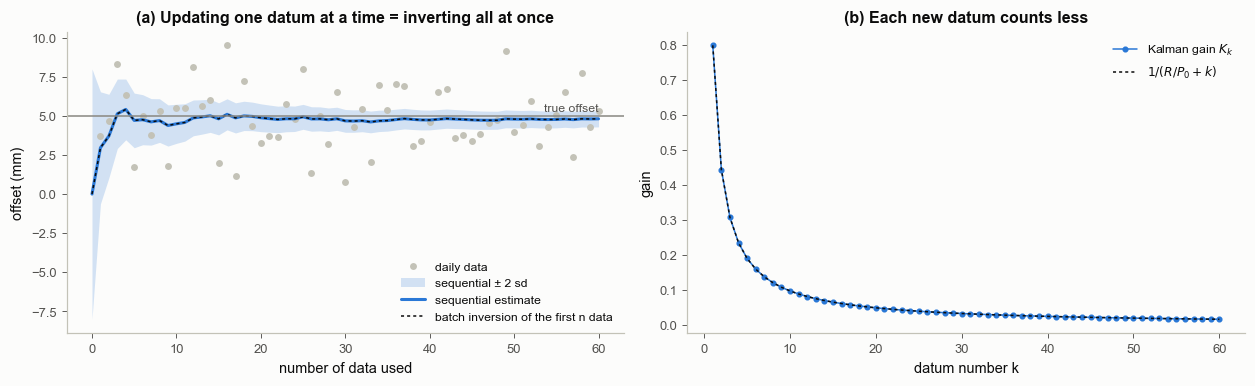

In [3]:
rng = np.random.default_rng(4)
c_true, x0, P0, R1 = 5.0, 0.0, 16.0, 4.0                    # antenna offset 5 mm; prior sd 4 mm; daily noise sd 2 mm
y1 = c_true + np.sqrt(R1) * rng.standard_normal(60)
xs_, Ps_, Ks_ = [x0], [P0], []
for y in y1:
    K = Ps_[-1] / (Ps_[-1] + R1)
    xs_.append(xs_[-1] + K * (y - xs_[-1])); Ps_.append((1 - K) * Ps_[-1]); Ks_.append(K)
xs_, Ps_ = np.array(xs_), np.array(Ps_)
n = np.arange(61)
Pbatch = 1 / (1 / P0 + n / R1)
xbatch = Pbatch * (x0 / P0 + np.r_[0, np.cumsum(y1)] / R1)
print("largest difference sequential - batch: mean %.1e mm, variance %.1e mm^2"
      % (np.abs(xs_ - xbatch).max(), np.abs(Ps_ - Pbatch).max()))

fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax = axs[0]
ax.plot(np.arange(1, 61), y1, "o", color="#c3c2b7", ms=3.5, label="daily data")
ax.fill_between(n, xs_ - 2 * np.sqrt(Ps_), xs_ + 2 * np.sqrt(Ps_), color=C_F, alpha=0.2, lw=0, label="sequential ± 2 sd")
ax.plot(n, xs_, color=C_F, lw=2, label="sequential estimate")
ax.plot(n, xbatch, color=S.INK, lw=1, ls=(0, (2, 2)), label="batch inversion of the first n data")
ax.axhline(c_true, color=S.MUTED, lw=1)
ax.text(60, c_true + 0.3, "true offset", ha="right", fontsize=8, color=S.INK2)
ax.set_xlabel("number of data used"); ax.set_ylabel("offset (mm)")
ax.set_title("(a) Updating one datum at a time = inverting all at once"); ax.legend(fontsize=8, loc="lower right")
ax = axs[1]
ax.plot(np.arange(1, 61), Ks_, "o-", color=C_F, ms=3, lw=1, label="Kalman gain $K_k$")
ax.plot(np.arange(1, 61), 1 / (R1 / P0 + np.arange(1, 61)), color=S.INK, lw=1, ls=(0, (2, 2)), label="$1/(R/P_0 + k)$")
ax.set_xlabel("datum number k"); ax.set_ylabel("gain")
ax.set_title("(b) Each new datum counts less"); ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-23_sequential_bayes")
plt.show()

**How to read it.** (a) The sequential estimate (blue) and the batch inversion of the same first $n$ data (dotted)
are the same curve: the printed difference is round-off. The band narrows as data accumulate. (b) The gain shrinks
like $1/k$: the tenth datum moves the estimate far less than the first, because by then the estimate already
carries the information of nine data.

**Common misreadings.** "A filter is an approximation of the batch solution." For a linear-Gaussian problem with a
constant unknown it is exactly the same answer, computed in pieces.

## 2. The Kalman gain is a trust ratio

**In plain words.** The gain says what fraction of the surprise to believe. If your current estimate is shaky and
the instrument is good, believe most of the surprise ($K$ near 1). If your estimate is already solid and the
instrument is noisy, believe little of it ($K$ near 0). The new estimate is a weighted average of forecast and
measurement, weighted by how certain each is.

**Precisely.** $K = P/(P + R) = 1/(1 + R/P)$ depends only on the ratio of forecast variance to measurement variance.
For vectors, $\mathbf K = \mathbf P\mathbf H^\top(\mathbf H\mathbf P\mathbf H^\top + \mathbf R)^{-1}$; with $\mathbf P = \mathbf C_m$, $\mathbf H = \mathbf G$, $\mathbf R = \mathbf C_d$ it is
the gain of the static linear inversion in 2.08 and 2.04.

saved figures/2-23_gain_trust_ratio.png


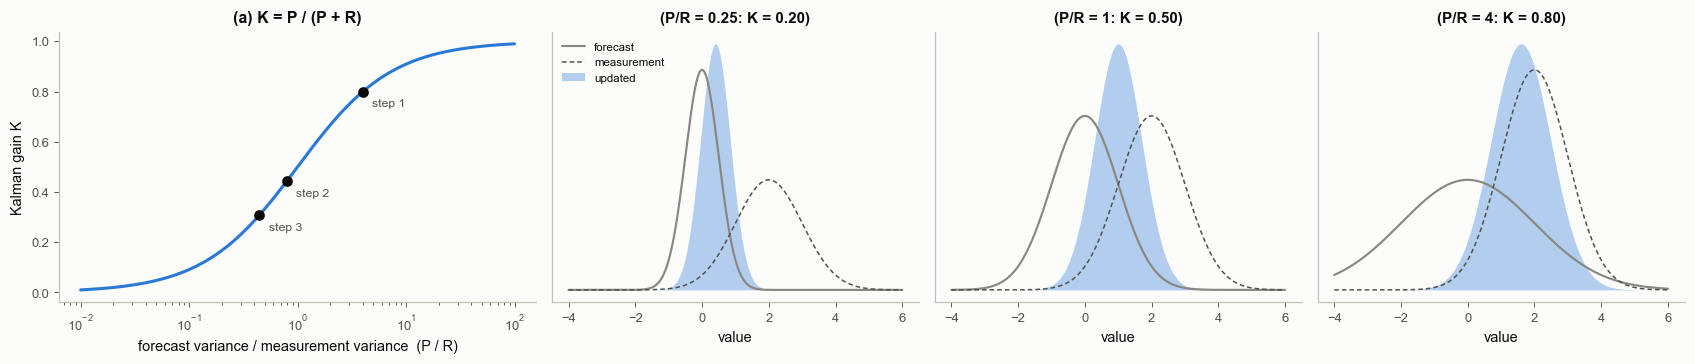

In [4]:
ratio = np.logspace(-2, 2, 200)
fig, axs = plt.subplots(1, 4, figsize=(15.5, 3.4), gridspec_kw=dict(width_ratios=[1.3, 1, 1, 1]))
ax = axs[0]
ax.semilogx(ratio, ratio / (1 + ratio), color=C_F, lw=2)
for Pw, lab in [(4.0, "step 1"), (0.8, "step 2"), (4 / 9, "step 3")]:
    ax.plot(Pw / 1.0, Pw / (Pw + 1.0), "o", color=S.INK, ms=6)
    ax.annotate(lab, (Pw, Pw / (Pw + 1)), textcoords="offset points", xytext=(6, -10), fontsize=8, color=S.INK2)
ax.set_xlabel("forecast variance / measurement variance  (P / R)")
ax.set_ylabel("Kalman gain K")
ax.set_title("(a) K = P / (P + R)")
grid_ = np.linspace(-4, 6, 600)
gpdf = lambda v, mu, var: np.exp(-0.5 * (v - mu) ** 2 / var) / np.sqrt(2 * np.pi * var)
for ax, (Pw, Rw) in zip(axs[1:], [(0.25, 1.0), (1.0, 1.0), (4.0, 1.0)]):
    K = Pw / (Pw + Rw)
    xf, yobs = 0.0, 2.0
    xa, Pa = xf + K * (yobs - xf), (1 - K) * Pw
    ax.plot(grid_, gpdf(grid_, xf, Pw), color=S.MUTED, lw=1.4, label="forecast")
    ax.plot(grid_, gpdf(grid_, yobs, Rw), color=S.INK2, lw=1.0, ls=(0, (3, 2)), label="measurement")
    ax.fill_between(grid_, gpdf(grid_, xa, Pa), color=C_F, alpha=0.35, lw=0, label="updated")
    ax.set_title(f"(P/R = {Pw / Rw:g}: K = {K:.2f})", fontsize=10)
    ax.set_yticks([]); ax.set_xlabel("value")
axs[1].legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-23_gain_trust_ratio")
plt.show()

**How to read it.** (a) The gain against the ratio of the two variances, with the three steps of the worked example
(the ratio shrinks each step, so the gain does). (b-d) Forecast at 0, measurement at 2: the updated estimate (blue)
sits a fraction K of the way towards the measurement and is narrower than both.

**Common misreadings.** "A large gain means the filter is good." It means the filter trusts the new data more than
its forecast, which is right only if the forecast really is that uncertain.

**The gain as a direction: one datum moves several unknowns.** With two unknowns and one datum, $\mathbf K$ is a
column of two numbers: how far each unknown moves per unit of surprise. Example: slip on two neighbouring fault
patches, $m_1$ and $m_2$, with a prior that makes them correlated (neighbours tend to slip alike, correlation ρ),
and one station that sees only patch 1 ($\mathbf H = (1\ \ 0)$). The datum says nothing about patch 2 directly, yet
the gain moves patch 2 too, through the prior correlation:
$\mathbf K = \mathbf P\mathbf H^\top/(\mathbf H\mathbf P\mathbf H^\top + R) = (P_{11},\ P_{21})^\top/(P_{11} + R)$.
Ensemble Kalman methods (2.24) rely on exactly this: the gain's off-diagonal part comes from the (cross-)covariance.

rho = 0.00: K = (0.800, 0.000); mean moves from (0, 0) to (1.20, 0.00); sd of m2 1.00 -> 1.00
rho = 0.60: K = (0.800, 0.480); mean moves from (0, 0) to (1.20, 0.72); sd of m2 1.00 -> 0.84
rho = 0.95: K = (0.800, 0.760); mean moves from (0, 0) to (1.20, 1.14); sd of m2 1.00 -> 0.53


saved figures/2-23_gain_vector.png


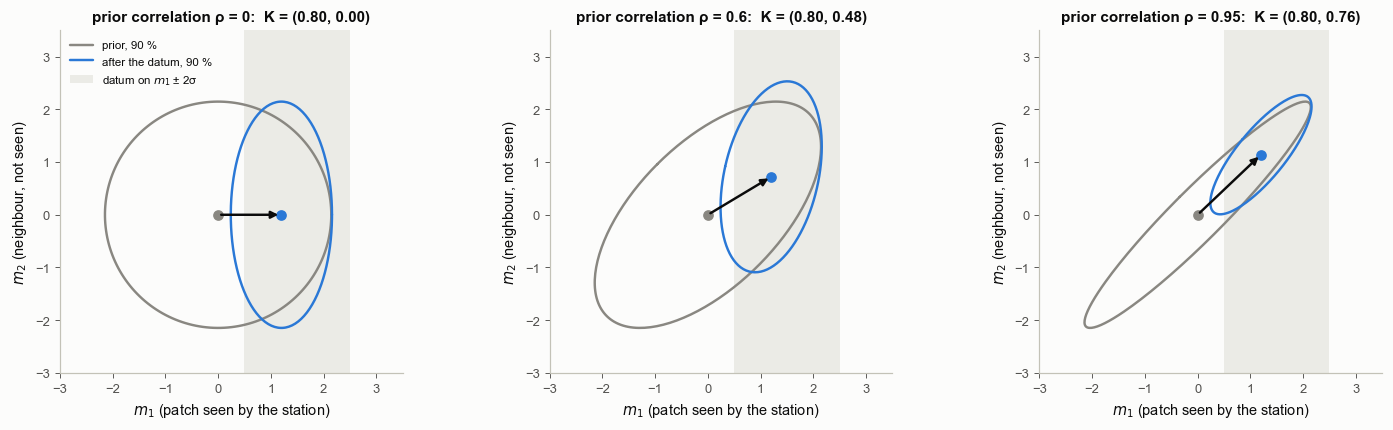

In [5]:
P_prior = lambda rho: np.array([[1.0, rho], [rho, 1.0]])
R_one, y_one, m_prior = 0.25, 1.5, np.zeros(2)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.0))
tt = np.linspace(0, 2 * np.pi, 200)
for ax, rho in zip(axs, [0.0, 0.6, 0.95]):
    Pm = P_prior(rho)
    H = np.array([[1.0, 0.0]])
    K = Pm @ H.T / (H @ Pm @ H.T + R_one)
    m_post = m_prior + (K * (y_one - H @ m_prior)).ravel()
    P_post = (np.eye(2) - K @ H) @ Pm
    for C_, m_, col, lab in [(Pm, m_prior, S.MUTED, "prior, 90 %"), (P_post, m_post, C_F, "after the datum, 90 %")]:
        ev, U = np.linalg.eigh(C_)
        pts = (U * np.sqrt(np.maximum(ev, 0) * 4.605)) @ np.stack([np.cos(tt), np.sin(tt)]) + m_[:, None]
        ax.plot(pts[0], pts[1], color=col, lw=1.6, label=lab)
    ax.axvspan(y_one - 2 * np.sqrt(R_one), y_one + 2 * np.sqrt(R_one), color=S.GRID, alpha=0.6, lw=0, label="datum on $m_1$ ± 2σ")
    ax.annotate("", xy=m_post, xytext=m_prior, arrowprops=dict(arrowstyle="-|>", color=S.INK, lw=1.6))
    ax.plot(*m_prior, "o", color=S.MUTED, ms=6); ax.plot(*m_post, "o", color=C_F, ms=6)
    ax.set_xlim(-3, 3.5); ax.set_ylim(-3, 3.5); ax.set_aspect("equal")
    ax.set_xlabel("$m_1$ (patch seen by the station)"); ax.set_ylabel("$m_2$ (neighbour, not seen)")
    ax.set_title(f"prior correlation ρ = {rho:g}:  K = ({K[0, 0]:.2f}, {K[1, 0]:.2f})", fontsize=10)
    print(f"rho = {rho:4.2f}: K = ({K[0, 0]:.3f}, {K[1, 0]:.3f}); mean moves from (0, 0) to ({m_post[0]:.2f}, {m_post[1]:.2f}); "
          f"sd of m2 {np.sqrt(Pm[1, 1]):.2f} -> {np.sqrt(P_post[1, 1]):.2f}")
axs[0].legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-23_gain_vector")
plt.show()

**How to read it.** The arrow is the update of the mean, $\mathbf K$ times the surprise. With uncorrelated patches
(left) only $m_1$ moves and the neighbour keeps its prior. As the prior correlation grows, the same datum moves $m_2$
further and shrinks its uncertainty too (printed): information about one patch reaches the other only through the
prior's off-diagonal covariance. A wrong correlation in the prior therefore puts wrong slip on patches no station
sees, which is one reason the choice of smoothing prior (2.09, 2.12) matters.

## 3. When the unknowns change: predict, then update

**In plain words.** Now the unknown moves: a GPS monument travels at a velocity that changes on day 200 (for
example when postseismic motion or a slow slip event starts). The filter needs a rule for how the state may change
between days. Here: position advances by velocity × time, and the velocity may wander a little each day. Before
each datum the filter *predicts* where the state went (and grows its uncertainty, because the state may have
wandered), then *updates* with the datum as in section 1.

**Precisely.** State $\mathbf x_k = (u_k, v_k)$ (position, velocity), observation $y_k = u_k + e_k$, $e_k\sim N(0, R)$:

$$\text{predict: }\ \mathbf x_k^- = \mathbf F\mathbf x_{k-1},\quad \mathbf P_k^- = \mathbf F\mathbf P_{k-1}\mathbf F^\top + \mathbf Q,\qquad
  \mathbf F = \begin{pmatrix}1 & \Delta t\\ 0 & 1\end{pmatrix},\quad \mathbf Q = q\begin{pmatrix}\Delta t^3/3 & \Delta t^2/2\\ \Delta t^2/2 & \Delta t\end{pmatrix}$$

$$\text{update: }\ \mathbf K_k = \mathbf P_k^-\mathbf H^\top(\mathbf H\mathbf P_k^-\mathbf H^\top + R)^{-1},\quad \mathbf x_k = \mathbf x_k^- + \mathbf K_k(y_k - \mathbf H\mathbf x_k^-),\quad
  \mathbf P_k = (\mathbf I - \mathbf K_k\mathbf H)\mathbf P_k^-,\qquad \mathbf H = (1\ \ 0).$$

$\mathbf Q$ is the **process noise**: how much the velocity may change per day ($q$ is its rate). It is the one knob of
the filter. A practical check of the knob is the normalised innovation squared, $\nu_k^2/S_k$ with
$S_k = \mathbf H\mathbf P_k^-\mathbf H^\top + R$: averaged over time it is about 1 when the filter's uncertainties are honest.

           q             rms velocity error  coverage of ±2 sd  mean NIS
    3.16e-08 too small            16.42 mm/yr               0.49      1.97
    3.16e-05 tuned                10.39 mm/yr               0.95      0.93
    3.16e-02 too large            68.43 mm/yr               1.00      0.84
saved figures/2-23_process_noise.png


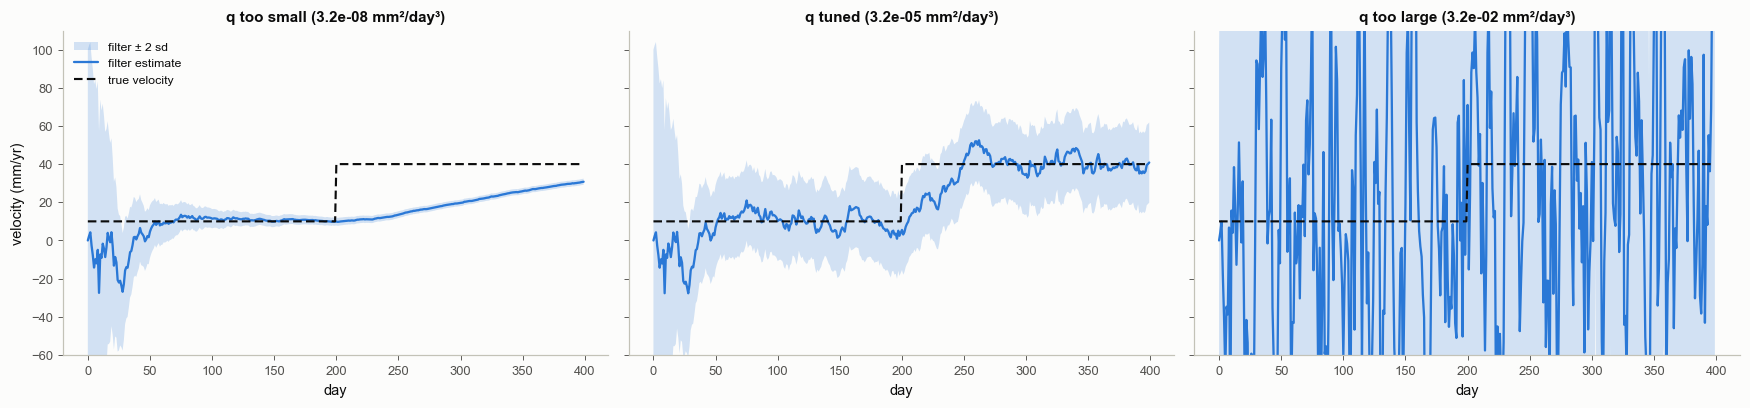

In [6]:
DAYS = 400
dt = 1.0
t3 = np.arange(DAYS) * dt
v_true = np.where(t3 < 200, 10.0, 40.0) / 365.25                  # mm/day: 10 mm/yr, then 40 mm/yr
u_true = np.r_[0, np.cumsum(v_true[:-1] * dt)]
R3 = 2.0 ** 2
y3 = u_true + np.sqrt(R3) * np.random.default_rng(11).standard_normal(DAYS)
F = np.array([[1.0, dt], [0.0, 1.0]])
H = np.array([[1.0, 0.0]])


def kalman(y, q, x0=np.zeros(2), P0=np.diag([10.0 ** 2, (50 / 365.25) ** 2])):
    """Linear Kalman filter for the position/velocity model. Returns filtered and predicted moments and the NIS."""
    Q = q * np.array([[dt ** 3 / 3, dt ** 2 / 2], [dt ** 2 / 2, dt]])
    x, Pm = x0.copy(), P0.copy()
    xf, Pf, xp, Pp, nis = [], [], [], [], []
    for k, yk in enumerate(y):
        if k > 0:
            x, Pm = F @ x, F @ Pm @ F.T + Q                        # predict
        xp.append(x.copy()); Pp.append(Pm.copy())
        Sk = (H @ Pm @ H.T + R3)[0, 0]
        K = (Pm @ H.T / Sk)[:, 0]
        nu = yk - (H @ x)[0]
        x = x + K * nu                                            # update
        IKH = np.eye(2) - np.outer(K, H[0])
        Pm = IKH @ Pm @ IKH.T + R3 * np.outer(K, K)               # Joseph form
        xf.append(x.copy()); Pf.append(Pm.copy()); nis.append(nu ** 2 / Sk)
    return dict(x=np.array(xf), P=np.array(Pf), xp=np.array(xp), Pp=np.array(Pp), nis=np.array(nis), Q=Q)


qs = np.logspace(-10, -3, 57)
rms_v = [np.sqrt(np.mean((kalman(y3, q)["x"][:, 1] - v_true) ** 2)) * 365.25 for q in qs]
q_best = qs[int(np.argmin(rms_v))]
Q_SET = {"too small": q_best / 1000, "tuned": q_best, "too large": q_best * 1000}
runs = {}
print(f"{'q':>12s} {'':10s} {'rms velocity error':>19s} {'coverage of ±2 sd':>18s} {'mean NIS':>9s}")
for lab, q in Q_SET.items():
    r_ = kalman(y3, q)
    runs[lab] = r_
    v, sv = r_["x"][:, 1], np.sqrt(r_["P"][:, 1, 1])
    cover = np.mean(np.abs(v - v_true) <= 2 * sv)
    print(f"{q:12.2e} {lab:10s} {np.sqrt(np.mean((v - v_true) ** 2)) * 365.25:15.2f} mm/yr {cover:18.2f} {r_['nis'].mean():9.2f}")

fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (lab, r_) in zip(axs, runs.items()):
    v, sv = r_["x"][:, 1] * 365.25, np.sqrt(r_["P"][:, 1, 1]) * 365.25
    ax.fill_between(t3, v - 2 * sv, v + 2 * sv, color=C_F, alpha=0.2, lw=0, label="filter ± 2 sd")
    ax.plot(t3, v, color=C_F, lw=1.5, label="filter estimate")
    ax.plot(t3, v_true * 365.25, color=C_T, lw=1.4, ls=(0, (4, 2)), label="true velocity")
    ax.set_title(f"q {lab} ({Q_SET[lab]:.1e} mm²/day³)", fontsize=10)
    ax.set_xlabel("day")
    ax.set_ylim(-60, 110)
axs[0].set_ylabel("velocity (mm/yr)")
axs[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-23_process_noise")
plt.show()

**How to read it.** The dashed line is the true velocity, the band the filter's ±2 standard deviations. With too
little process noise (left) the filter believes the velocity hardly changes: it takes a long time to follow the
jump on day 200, and its band is so narrow that the truth falls outside it. With too much (right) the velocity
estimate chases the daily noise. The tuned value follows the jump within about two months, with an honest band. The printed
table puts numbers on it, including the mean normalised innovation squared: it moves away from 1 when $q$ is
badly set, which is how $q$ is checked in practice without knowing the truth.

**Common misreadings.** "Process noise is a nuisance parameter." It encodes your belief about how fast the Earth can
change, and it decides what the filter can see: no filter can follow a change faster than its $\mathbf Q$ allows.

## 4. Filter or smoother?

**In plain words.** A filter estimates each day from the data up to that day; that is what real-time monitoring
needs. For a study done afterwards, each day can also use the data *after* it. The smoother runs backwards
through the filter's results and revises every day with the later data. It sees the jump on day 200 without the
filter's lag and with a narrower band.

**Precisely.** Rauch-Tung-Striebel smoother (Rauch, Tung & Striebel 1965), backwards from the last day:

$$\mathbf C_k = \mathbf P_k\mathbf F^\top(\mathbf P_{k+1}^-)^{-1},\qquad
  \mathbf x_k^s = \mathbf x_k + \mathbf C_k(\mathbf x_{k+1}^s - \mathbf x_{k+1}^-),\qquad
  \mathbf P_k^s = \mathbf P_k + \mathbf C_k(\mathbf P_{k+1}^s - \mathbf P_{k+1}^-)\mathbf C_k^\top .$$

Two checks: on the last day smoother and filter agree; with $q = 0$ (a constant velocity) the smoother equals one batch
least-squares fit of a straight line to all data with the same prior.

last day: smoother - filter = 0.0e+00
q = 0: smoothed velocity 0.068773 mm/day, batch least squares 0.068773 mm/day; smoothed position on day 0 -4.0822, batch -4.0822
tuned q: rms velocity error filter 10.39 mm/yr, smoother 3.49 mm/yr; mean ±2 sd width filter 49.4, smoother 22.8 mm/yr
saved figures/2-23_filter_vs_smoother.png


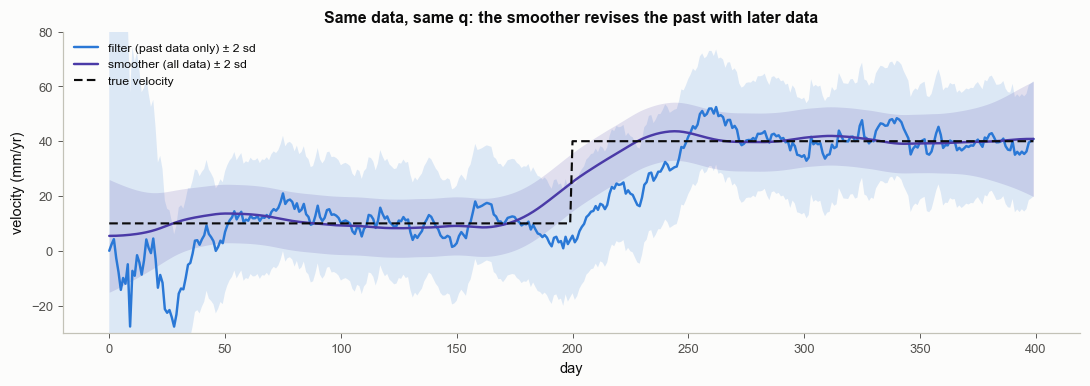

In [7]:
def rts(r_):
    xs_s, Ps_s = r_["x"].copy(), r_["P"].copy()
    for k in range(len(xs_s) - 2, -1, -1):
        Ck = r_["P"][k] @ F.T @ np.linalg.inv(r_["Pp"][k + 1])
        xs_s[k] = r_["x"][k] + Ck @ (xs_s[k + 1] - r_["xp"][k + 1])
        Ps_s[k] = r_["P"][k] + Ck @ (Ps_s[k + 1] - r_["Pp"][k + 1]) @ Ck.T
    return xs_s, Ps_s


sm_x, sm_P = rts(runs["tuned"])
print("last day: smoother - filter = %.1e" % np.abs(sm_x[-1] - runs["tuned"]["x"][-1]).max())
r0 = kalman(y3, 0.0)
s0, _ = rts(r0)
A = np.column_stack([np.ones(DAYS), t3])                            # u(t) = u0 + v t
P0m = np.diag([10.0 ** 2, (50 / 365.25) ** 2])
Cpost = np.linalg.inv(np.linalg.inv(P0m) + A.T @ A / R3)
batch = Cpost @ (A.T @ y3 / R3)
print("q = 0: smoothed velocity %.6f mm/day, batch least squares %.6f mm/day; smoothed position on day 0 %.4f, batch %.4f"
      % (s0[0, 1], batch[1], s0[0, 0], batch[0]))
v_f, v_s = runs["tuned"]["x"][:, 1], sm_x[:, 1]
print("tuned q: rms velocity error filter %.2f mm/yr, smoother %.2f mm/yr; mean ±2 sd width filter %.1f, smoother %.1f mm/yr"
      % (np.sqrt(np.mean((v_f - v_true) ** 2)) * 365.25, np.sqrt(np.mean((v_s - v_true) ** 2)) * 365.25,
         4 * np.mean(np.sqrt(runs["tuned"]["P"][:, 1, 1])) * 365.25, 4 * np.mean(np.sqrt(sm_P[:, 1, 1])) * 365.25))

fig, ax = plt.subplots(figsize=(10, 3.6))
for xx_, PP_, col, lab in [(runs["tuned"]["x"], runs["tuned"]["P"], C_F, "filter (past data only)"),
                           (sm_x, sm_P, C_S, "smoother (all data)")]:
    v, sv = xx_[:, 1] * 365.25, np.sqrt(PP_[:, 1, 1]) * 365.25
    ax.fill_between(t3, v - 2 * sv, v + 2 * sv, color=col, alpha=0.15, lw=0)
    ax.plot(t3, v, color=col, lw=1.6, label=lab + " ± 2 sd")
ax.plot(t3, v_true * 365.25, color=C_T, lw=1.4, ls=(0, (4, 2)), label="true velocity")
ax.set_xlabel("day"); ax.set_ylabel("velocity (mm/yr)"); ax.set_ylim(-30, 80)
ax.set_title("Same data, same q: the smoother revises the past with later data")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-23_filter_vs_smoother")
plt.show()

**How to read it.** The filter (blue) needs days after day 200 to notice the jump, because it cannot use them; the
smoother (violet) uses them and changes close to the true date, with a narrower band (numbers printed above). The
two checks above it hold to round-off: a smoother with zero process noise is just a batch least-squares fit.

**Common misreadings.** "Use the filter output for a postseismic study." For a study after the fact the smoother is
the right estimate; the filter output is what you would have known in real time.

## 5. A Network Inversion Filter in miniature

**In plain words.** Segall & Matthews (1997) put fault slip into the Kalman state: the state is the slip and slip
rate on every fault patch, the observations are GPS displacements predicted through Green's functions, and the
process noise lets slip rate change in time. The filter and smoother then show *where* and *when* the fault slipped.

**Precisely.** Three patches of the antiplane fault (0-5, 5-15 and 15-30 km depth), ten stations. State
$\mathbf x_k = (\mathbf s_k, \dot{\mathbf s}_k)$ (slip and slip rate per patch, mm and mm/day); slip advances by rate × Δt and each
rate wanders as a random walk; observations $\mathbf d_k = \mathbf G\mathbf s_k + \mathbf e_k$, σ = 2 mm. Truth: the shallow patch is
locked, the deep patch creeps steadily at 30 mm/yr, and the middle patch has a slow slip event from day 100 to day
160. The real NIF also estimates benchmark wobble, reference-frame terms and its smoothing hyperparameters; this toy
keeps only the core.

total slip of the slow slip event: 30 mm; largest surface signal it makes: 5.0 mm (noise 2 mm per day)


process-noise rate chosen on a grid (smallest smoothed rate error, a synthetic-test luxury): 1.0e-03 (mm/day)^2/day
shallow (0-5 km) : final slip filter   -0.0 ±  1.6 mm, true    0.0 mm
middle (5-15 km) : final slip filter   26.7 ±  4.3 mm, true   30.0 mm
deep (15-30 km)  : final slip filter   28.5 ±  5.2 mm, true   24.6 mm


saved figures/2-23_network_inversion_filter.png


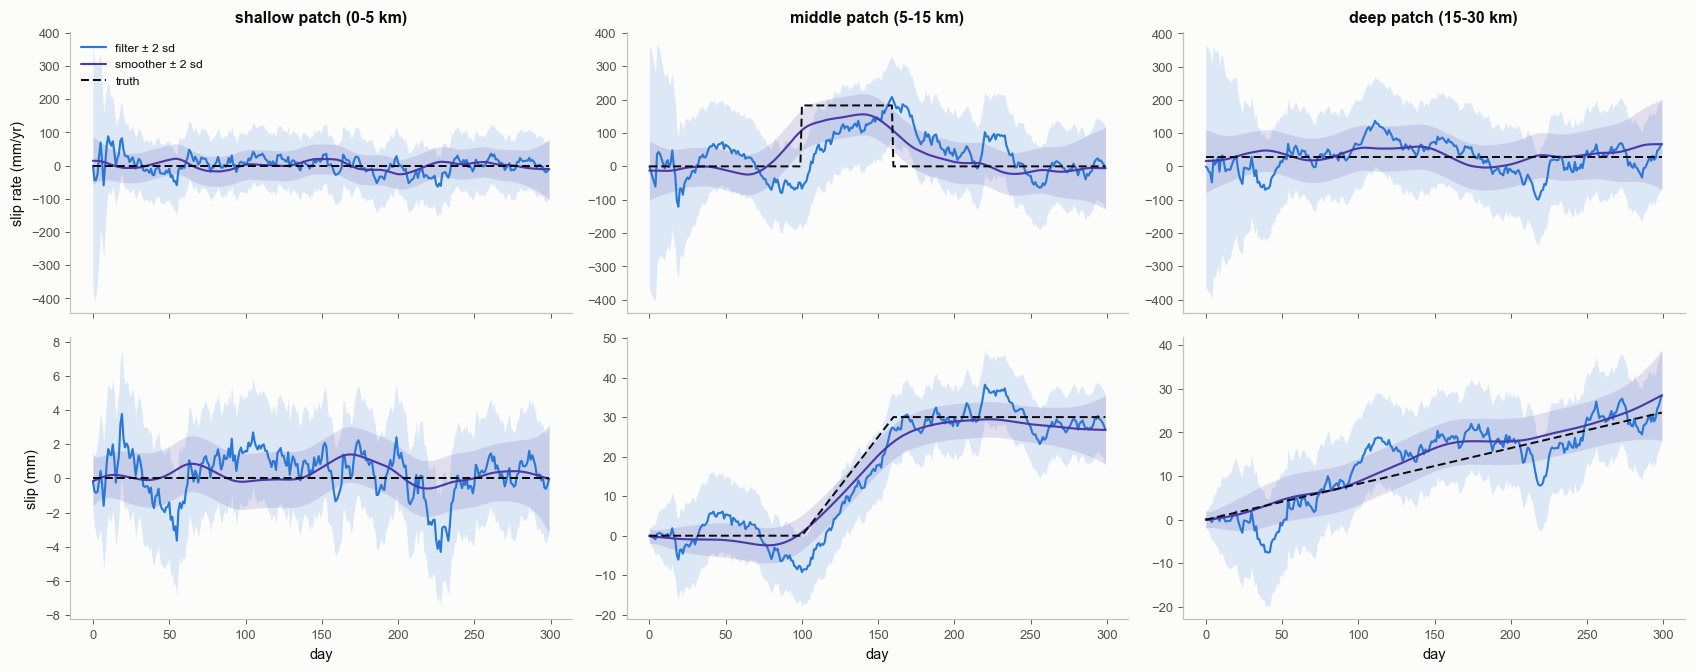

In [8]:
edges = np.array([0.0, 5.0, 15.0, 30.0])
xst = np.array([2.0, 5.0, 10.0, 20.0, 40.0])
xst = np.sort(np.r_[-xst, xst])
Gn = np.array([[(np.arctan(edges[j + 1] / x) - np.arctan(edges[j] / x)) / np.pi for j in range(3)] for x in xst])  # mm per mm
ND = 300
tn = np.arange(ND)
rate_true = np.zeros((ND, 3))
rate_true[:, 2] = 30.0 / 365.25
rate_true[(tn >= 100) & (tn < 160), 1] = 0.5
slip_true = np.vstack([np.zeros(3), np.cumsum(rate_true[:-1], axis=0)])
dN = slip_true @ Gn.T + 2.0 * np.random.default_rng(5).standard_normal((ND, xst.size))
print("total slip of the slow slip event: %.0f mm; largest surface signal it makes: %.1f mm (noise 2 mm per day)"
      % (slip_true[-1, 1], np.abs(Gn[:, 1] * slip_true[-1, 1]).max()))

Fn = np.block([[np.eye(3), dt * np.eye(3)], [np.zeros((3, 3)), np.eye(3)]])
Hn = np.hstack([Gn, np.zeros((xst.size, 3))])
Rn = 4.0 * np.eye(xst.size)


def nif(d, q_rate):
    Qn = np.kron(np.array([[dt ** 3 / 3, dt ** 2 / 2], [dt ** 2 / 2, dt]]), q_rate * np.eye(3))
    x, Pm = np.zeros(6), np.diag([1.0] * 3 + [0.5 ** 2] * 3)
    xf, Pf, xp, Pp = [], [], [], []
    for k in range(len(d)):
        if k > 0:
            x, Pm = Fn @ x, Fn @ Pm @ Fn.T + Qn
        xp.append(x.copy()); Pp.append(Pm.copy())
        Sk = Hn @ Pm @ Hn.T + Rn
        K = np.linalg.solve(Sk, Hn @ Pm).T
        x = x + K @ (d[k] - Hn @ x)
        IKH = np.eye(6) - K @ Hn
        Pm = IKH @ Pm @ IKH.T + K @ Rn @ K.T
        xf.append(x.copy()); Pf.append(Pm.copy())
    xf, Pf, xp, Pp = map(np.array, (xf, Pf, xp, Pp))
    xs_s, Ps_s = xf.copy(), Pf.copy()
    for k in range(len(d) - 2, -1, -1):
        Ck = Pf[k] @ Fn.T @ np.linalg.inv(Pp[k + 1])
        xs_s[k] = xf[k] + Ck @ (xs_s[k + 1] - xp[k + 1])
        Ps_s[k] = Pf[k] + Ck @ (Ps_s[k + 1] - Pp[k + 1]) @ Ck.T
    return xf, Pf, xs_s, Ps_s


q_grid = np.logspace(-7, -2, 21)
err_q = []
for q in q_grid:
    _, _, xs_s, _ = nif(dN, q)
    err_q.append(np.sqrt(np.mean((xs_s[:, 3:] - rate_true) ** 2)))
q_nif = q_grid[int(np.argmin(err_q))]
xf, Pf, xs_s, Ps_s = nif(dN, q_nif)
print(f"process-noise rate chosen on a grid (smallest smoothed rate error, a synthetic-test luxury): {q_nif:.1e} (mm/day)^2/day")
for j, name in enumerate(["shallow (0-5 km)", "middle (5-15 km)", "deep (15-30 km)"]):
    print(f"{name:17s}: final slip filter {xf[-1, j]:6.1f} ± {np.sqrt(Pf[-1, j, j]):4.1f} mm, true {slip_true[-1, j]:6.1f} mm")

fig, axs = plt.subplots(2, 3, figsize=(15.5, 6.2), sharex=True)
names = ["shallow patch (0-5 km)", "middle patch (5-15 km)", "deep patch (15-30 km)"]
for j in range(3):
    for row, (off, scale, unit) in enumerate([(3, 365.25, "slip rate (mm/yr)"), (0, 1.0, "slip (mm)")]):
        ax = axs[row, j]
        for xx_, PP_, col, lab in [(xf, Pf, C_F, "filter"), (xs_s, Ps_s, C_S, "smoother")]:
            mu, sd = xx_[:, off + j] * scale, np.sqrt(PP_[:, off + j, off + j]) * scale
            ax.fill_between(tn, mu - 2 * sd, mu + 2 * sd, color=col, alpha=0.15, lw=0)
            ax.plot(tn, mu, color=col, lw=1.4, label=lab + " ± 2 sd")
        truth = (rate_true[:, j] * 365.25) if row == 0 else slip_true[:, j]
        ax.plot(tn, truth, color=C_T, lw=1.3, ls=(0, (4, 2)), label="truth")
        if row == 0:
            ax.set_title(names[j], fontsize=10.5)
        if j == 0:
            ax.set_ylabel(unit)
        if row == 1:
            ax.set_xlabel("day")
axs[0, 0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-23_network_inversion_filter")
plt.show()

**How to read it.** Top row: slip rate per patch; bottom row: cumulative slip. The smoother (violet) recovers the
slow slip event on the middle patch, its timing and its total slip, while the filter (blue) responds late and with a
wider band. The deep creep is recovered more loosely (deep patches make broad, weak signals, 2.07), and the locked
shallow patch stays near zero (final values printed above).

**Common misreadings.** "The NIF finds the slip history from the data alone." Its process noise is a smoothness prior
in time, and the Green's functions a resolution limit in space; both shape what it can see, as the spatial prior
does in a static inversion.

## 6. The Kalman family

| method | state changes in time? | forward model | how the gain is computed | notebook |
|---|---|---|---|---|
| static linear inversion | no | linear | exactly, $\mathbf C_m\mathbf G^\top(\mathbf G\mathbf C_m\mathbf G^\top + \mathbf C_d)^{-1}$ | 2.08 |
| Kalman filter / RTS smoother | yes | linear | exactly, from propagated covariances | this one |
| extended Kalman filter | yes or no | nonlinear, linearised (Jacobian, 2.17) | from the tangent | 2.25 |
| ensemble Kalman filter (EnKF) | yes | any (forward runs only) | from ensemble covariances | 2.24 |
| EKI / EnKI | no (iterations stand in for time) | any (forward runs only) | from ensemble covariances; EnKI tempers the data with θ | 2.24 |

**In practice.** The Network Inversion Filter (Segall & Matthews 1997) and its extended form (ENIF, McGuire & Segall
2003) are the Kalman filter with slip in the state; Qiu et al. (2018) used a modified ENIF to image afterslip and
viscous strain after the Sumatran earthquakes. Ensemble Kalman inversion (2.24) applies the same update to a static
problem: the gain is built from an ensemble instead of propagated covariances, and a data weight θ plays the role
that time plays here, letting the data in gradually.

Next: [**2.24 · Ensemble Kalman methods: EnKF, EKI, EnKI**](2-24_ensemble_kalman.ipynb).